<a href="https://colab.research.google.com/github/lilianeuwase2/ABILANE_NISRinfographic/blob/main/nisr_calculations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NISR Infographic Competition 2026 · "Same Harvest, Bigger Food Bill"**

**Calculations and chart code**

This notebook shows where every number and chart on our infographic comes from. It reads two NISR files, calculates each figure, checks our CPI data against NISR's own publication (Step 10), and then draws the charts we placed in Canva.

**How to run it in Google Colab**
1. Go to [colab.research.google.com](https://colab.research.google.com), choose **File → Upload notebook**, and pick this file.
2. Click the **folder icon** on the left, then the **upload** icon, and upload both NISR files. Keep their names exactly as they are:
   - `SAS 2025_Annual Tables.xlsx`
   - `CPI_time_series_August 2026.xls`
3. Choose **Runtime → Run all**. The CPI file is big, so Step 7 takes up to a minute.

You can also run it in Jupyter on your own computer: put the notebook in the same folder as the two files.

> Python does the **maths** here and draws the charts. The infographics themselves are designed in Canva.

## Step 1: Load the tools

A **library** is code someone else wrote that we can reuse. We need:

- **pandas**, which reads Excel files and works with tables. A table in pandas is called a **DataFrame**. A single column or row is called a **Series**.
- **xlrd**, which lets pandas read the old `.xls` format the CPI file uses.

The `%pip install` line installs anything that's missing. In Colab most of it is already there.

In [1]:
%pip install -q xlrd openpyxl

import warnings
from decimal import Decimal, ROUND_HALF_UP

import pandas as pd

warnings.filterwarnings("ignore")      # hides a harmless warning the SAS file triggers

SAS_FILE = "SAS 2025_Annual Tables.xlsx"
CPI_FILE = "CPI_time_series_August 2026.xls"
print("Ready!")

Ready!


r() rounds halves up (37.25 to 37.3), because Python's built-in round() rounds halves to the even digit (37.25 to 37.2). It is used wherever a number is rounded for the poster.

In [2]:
def r(x, decimals=1):
    # Everyday rounding: halves go up (37.25 → 37.3). decimals=-1 rounds to the nearest 10.
    return float(Decimal(str(x)).quantize(Decimal(1).scaleb(-decimals), rounding=ROUND_HALF_UP))

## Step 2: Open SAS Table 0

The SAS file has many sheets. **Table 0** is the summary: one row per indicator, with 9 numbers per row (2023, 2024, and 2025) and one column per season.

`header=None` tells pandas *not* to use the first row as column names, because NISR's first rows are titles. pandas then numbers the rows and columns from **0**:

`iloc[rows, columns]` picks cells by their position. `sas.iloc[0:12, 0:11]` means "rows 0 to 11, columns 0 to 10" (the end number is not included).

In [3]:
sas = pd.read_excel(SAS_FILE, sheet_name="Table 0", header=None)
sas.iloc[0:12, 0:11]

,0,1,2,3,4,5,6,7,8,9,10
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Table 0: Summary of Seasonal Agricultural Surv...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,SAS main indicators,SAS 2023,NaN,NaN,SAS 2024,NaN,NaN,SAS 2025,NaN,NaN
4,NaN,NaN,Season,NaN,NaN,Season,NaN,NaN,Season,NaN,NaN
5,NaN,NaN,A,B,C,A,B,C,A,B,C
6,NaN,Cultivated area for major crops (Ha),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,Maize,226982,93927,-,249435,92944,NaN,244095.2,93004.99,NaN
8,NaN,Sorghum,38979,121079,-,34720,120005,NaN,40352.8,107195.15084,NaN
9,NaN,Paddy rice,16135,16678,-,17173,17994,NaN,17311.61,17969.566365,NaN


## Step 3: Split Table 0 into sections

Table 0 is divided into sections such as *Production* and *Yield*. Each section starts with a title row that has no numbers. We turn the table into a dictionary: section → row name → season → value.



In [4]:
SEASONS = ["2023 A", "2023 B", "2023 C",
           "2024 A", "2024 B", "2024 C",
           "2025 A", "2025 B", "2025 C"]


def clean(text):
    # NISR writes some labels with invisible special spaces and a 'v ' bullet. Remove them.
    text = str(text).replace("\xa0", " ").strip()
    if text.startswith("v "):
        text = text[2:].strip()
    return text


sections = {}
current = None
for i in range(len(sas)):
    label = sas.iloc[i, 1]                    # column B holds the labels
    if pd.isna(label):                        # an empty row: skip it
        continue
    # columns C to K hold the numbers; '-' (no data) becomes NaN, which means "empty"
    numbers = pd.to_numeric(sas.iloc[i, 2:11], errors="coerce")
    if numbers.isna().all():                  # no numbers at all: a section title
        current = clean(label)
        sections[current] = {}
    elif current is not None:                 # a row of numbers inside the current section
        sections[current][clean(label)] = dict(zip(SEASONS, numbers))

for name, rows in sections.items():
    print(f"{name}: {len(rows)} rows")

Table 0: Summary of Seasonal Agricultural Survey main indicators: 0 rows
SAS main indicators: 0 rows
Cultivated area for major crops (Ha): 18 rows
Harvested area for major crops (Ha): 18 rows
Production for major crops (MT): 18 rows
Yield for major crops (MT/ha): 18 rows
Agricultural inputs: % of farmers who used: 4 rows
Agricultural practices: % of farmers who practiced: 2 rows
Agricultural area: 8 rows


## Step 4: Total harvest per year

The harvest of one crop in one year is **Season A + Season B + Season C**. Then we add all the crops together.

Two rows are left out:
- **"Banana"** is already cooking + dessert + beer banana added together, so counting it would count bananas twice.
- **"Banana for beer"** is not eaten as food.

**Percentage change:** change = (new ÷ old − 1) × 100.

In [5]:
def section(start):
    # Find a section by the first words of its title, e.g. "Production"
    for title, rows in sections.items():
        if title.startswith(start):
            return rows


def pct_change(new, old):
    return (new / old - 1) * 100


production = section("Production")


def year_total(crop, year):
    # Add Seasons A, B and C for one crop. .sum() skips empty (NaN) seasons.
    values = [production[crop][f"{year} {season}"] for season in "ABC"]
    return pd.Series(values).sum()


NOT_COUNTED = ["Banana", "Banana for beer"]
counted = [crop for crop in production if crop not in NOT_COUNTED]

harvest = {}
for year in [2023, 2024, 2025]:
    harvest[year] = sum(year_total(crop, year) for crop in counted)
    print(f"{year}: {harvest[year]:,.0f} tonnes = {harvest[year] / 1_000_000:.2f} million tonnes")

print(f"\nChange 2024 → 2025: {pct_change(harvest[2025], harvest[2024]):+.1f}%")
print(f"Change 2023 → 2025: {pct_change(harvest[2025], harvest[2023]):+.1f}%")

2023: 6,813,865 tonnes = 6.81 million tonnes
2024: 7,077,280 tonnes = 7.08 million tonnes
2025: 7,151,741 tonnes = 7.15 million tonnes

Change 2024 → 2025: +1.1%
Change 2023 → 2025: +5.0%


**Check the data:** "Banana" should be the sum of the three banana rows, the difference below is about 0. A difference of 1 or 2 is rounding to whole tonnes.

In [6]:
for year in [2023, 2024, 2025]:
    parts = sum(year_total(c, year) for c in ["Cooking banana", "Dessert banana", "Banana for beer"])
    print(f"{year}: Banana − (the three banana rows) = {year_total('Banana', year) - parts:.1f}")

2023: Banana − (the three banana rows) = -1.0
2024: Banana − (the three banana rows) = -1.0
2025: Banana − (the three banana rows) = -0.0


## Step 5: Crop by crop

We compare 10 everyday staples between 2024 and 2025. The dictionary maps **NISR's name → the name on our chart** (NISR says "Bean" and "Paddy rice").

In [7]:
STAPLES = {"Maize": "Maize", "Sorghum": "Sorghum", "Wheat": "Wheat", "Bean": "Beans",
           "Sweet potato": "Sweet potato", "Paddy rice": "Rice", "Cooking banana": "Cooking banana",
           "Vegetables": "Vegetables", "Irish potato": "Irish potato", "Cassava": "Cassava"}

crops = pd.DataFrame({
    "crop": list(STAPLES.values()),
    "2024 (t)": [year_total(c, 2024) for c in STAPLES],
    "2025 (t)": [year_total(c, 2025) for c in STAPLES],
})
crops["change %"] = pct_change(crops["2025 (t)"], crops["2024 (t)"])
crops = crops.sort_values("change %")          # biggest fall first

fell = (crops["change %"] < 0).sum()
print(f"{fell} of {len(crops)} staples produced less in 2025\n")
crops.round(1)

5 of 10 staples produced less in 2025



,crop,2024 (t),2025 (t),change %
2,Wheat,16416.0,14810.7,-9.8
0,Maize,627086.0,598956.4,-4.5
1,Sorghum,187766.0,180649.3,-3.8
4,Sweet potato,1398052.0,1350124.2,-3.4
3,Beans,478427.0,474354.7,-0.9
5,Rice,141932.0,142656.2,0.5
6,Cooking banana,1103779.0,1117360.9,1.2
7,Vegetables,389462.0,398704.1,2.4
8,Irish potato,827355.0,884769.8,6.9
9,Cassava,1301338.0,1395415.3,7.2


## Step 6: Yields, land and farming practices

These numbers are read straight from Table 0, with no maths needed. We look them up like this: `section` → row name → season.

- **Yield** is harvest per hectare: how many tonnes one hectare of land produced.
- **Farmland share** = farmland ÷ all of Rwanda's land × 100.

In [8]:
yields = section("Yield")
inputs = section("Agricultural inputs")
practices = section("Agricultural practices")
land = section("Agricultural area")

for nisr_name, name in [("Bean", "Beans"), ("Maize", "Maize"), ("Irish potato", "Irish potato"), ("Cassava", "Cassava")]:
    print(f"{name}: {yields[nisr_name]['2025 A']:.2f} tonnes per hectare (Season A 2025)")

farmland = land["Agriculture land (,000Ha)"]["2025 A"] / land["Total land area (,000Ha)"]["2025 A"] * 100
print(f"\nFarmland share of Rwanda's land, Season A 2025: {farmland:.1f}%")
print(f"Farmers who irrigated, Season A 2025: {practices['Irrigation']['2025 A']}%")
print(f"Farmers who used improved seeds: Season A {inputs['Improved seeds']['2025 A']}%, "
      f"Season B {inputs['Improved seeds']['2025 B']}%")

Beans: 0.70 tonnes per hectare (Season A 2025)
Maize: 1.99 tonnes per hectare (Season A 2025)
Irish potato: 8.74 tonnes per hectare (Season A 2025)
Cassava: 13.54 tonnes per hectare (Season A 2025)

Farmland share of Rwanda's land, Season A 2025: 58.9%
Farmers who irrigated, Season A 2025: 13.43%
Farmers who used improved seeds: Season A 37.25%, Season B 17.99%


## Step 7: Read the CPI file

**CPI = Consumer Price Index.** Every month NISR checks the price of the same basket of goods. The index was set to **100 in February 2014** (the *base month*). So 150 means prices are 1.5 times what they were then.

Every CPI sheet has the same layout:
- Excel **row 4** holds the months, starting in column G.
- **Column D** holds the name of each item and **column E** its **weight**: how much of an average household's spending goes on it, out of 10,000.
- The index values run to the right, one column per month. We label every value with its month (for example `"2026-08"`), so we can look values up by month later.

In [9]:
%pip install -q python-calamine

cpi_book = pd.ExcelFile(CPI_FILE, engine="calamine")


def read_cpi_sheet(sheet_name):
    raw = pd.read_excel(cpi_book, sheet_name=sheet_name, header=None)
    months = list(pd.to_datetime(raw.iloc[3, 5:]).dt.strftime("%Y-%m"))   # e.g. '2026-08'
    rows = []
    for i in range(4, len(raw)):
        label = raw.iloc[i, 3]
        if pd.isna(label) or str(label).startswith("Source"):
            continue
        values = pd.to_numeric(raw.iloc[i, 5:], errors="coerce")
        values.index = months                     # label every value with its month
        rows.append({"label": clean(label), "weight": float(raw.iloc[i, 4]), "series": values})
    return rows


def find(rows, label, after=None):
    # Find a row by its name. 'after' is for names that appear twice in one sheet.
    start = 0
    if after:
        start = [r["label"] for r in rows].index(after) + 1
    for r in rows[start:]:
        if r["label"] == label:
            return r


all_rwanda = read_cpi_sheet("All Rwanda")
rural = read_cpi_sheet("Rural")
urban = read_cpi_sheet("Urban")
other = read_cpi_sheet("Other_Indices")         # extra indices, published for urban areas only

FOOD = "Food and non-alcoholic beverages"
food = find(all_rwanda, FOOD)["series"]
general = find(all_rwanda, "GENERAL INDEX (CPI)")["series"]
print("Months from", food.index[0], "to", food.index[-1])
food.tail()                                      # the last 5 months

Months from 2009-02 to 2026-08


,6
2026-04,280.004193
2026-05,282.652726
2026-06,281.671793
2026-07,283.666928
2026-08,296.772043


## Step 8: Food prices since 2014

**Same year as the harvest.** The SAS report is about **2025**, so we compare prices for **2025** too. The CPI file goes on to August 2026, but we don't mix those months into our comparisons.

- `food.shift(12)` slides every value 12 months along, so each month lines up with **the same month a year earlier**. Dividing the two gives the change over one year for every month at once.
- Yearly average = mean of the 12 months of each year. Only full years (2010 to 2025) are compared, because the file starts in February 2009 and stops in August 2026.

In [10]:
yearly_change = pct_change(food, food.shift(12))
print(f"Biggest jump in one year: {yearly_change.max():+.1f}% in {yearly_change.idxmax()}")

yearly_avg = food.groupby(lambda month: int(month[:4])).mean()
full_years = yearly_avg.loc[2010:2025]
print(f"\nFebruary 2014 (base month): {food['2014-02']:.1f}")
print(f"2025 yearly average:        {yearly_avg[2025]:.1f}  →  {yearly_avg[2025] / food['2014-02']:.2f} times February 2014")
print(f"Highest yearly average:     {full_years.max():.1f} in {full_years.idxmax()}")
print(f"\nYearly average 2024 vs 2023: {pct_change(yearly_avg[2024], yearly_avg[2023]):+.1f}%  (the dip)")
print(f"Yearly average 2025 vs 2024: {pct_change(yearly_avg[2025], yearly_avg[2024]):+.1f}%")

Biggest jump in one year: +64.5% in 2022-11

February 2014 (base month): 100.0
2025 yearly average:        255.7  →  2.56 times February 2014
Highest yearly average:     255.7 in 2025

Yearly average 2024 vs 2023: -2.7%  (the dip)
Yearly average 2025 vs 2024: +4.5%


## Step 9: Other prices in the same year, 2024 → 2025

We write one small function, `year_change`, that compares the **2025 yearly average** with the **2024 yearly average**, and it is used for every price index, so every comparison on the poster covers the same period as the harvest.

In [11]:
def year_change(series):
    averages = series.groupby(lambda month: int(month[:4])).mean()
    return pct_change(averages[2025], averages[2024])


rural_food = find(rural, FOOD)["series"]
urban_food = find(urban, FOOD)["series"]

print(f"Food prices, All Rwanda:  {year_change(food):+.1f}%")
print(f"All prices (general CPI): {year_change(general):+.1f}%")
print(f"Food prices, rural:       {year_change(rural_food):+.1f}%")
print(f"Food prices, urban:       {year_change(urban_food):+.1f}%")

Food prices, All Rwanda:  +4.5%
All prices (general CPI): +5.9%
Food prices, rural:       +4.0%
Food prices, urban:       +5.5%


Notice all prices rose a little more than food prices in 2025, so a flat harvest is one reason food costs more, but not the only one.

## Step 10: The 2025 CPI, month by month, checked against NISR's own publication

The file is name "August 2026" because that is when NIRS published it. It holds every month from February 2009 to August 2009 to August 2026, including all 12 months of 2025. The table shows the 2025 CPI by month and the 2025 average we will use on the poster.

We then check our file against NISR's CPI publication for September 2025, which reports the change from September 2024 to September 2025. We calculate the same changes from our file; if every row says 'True', the two agree. The reason we use the time series file is becasue the publication stops at September, so it cannot give the full year average.

In [12]:
# The 2025 CPI, month by month (February 2014 = 100)
cpi_2025 = pd.DataFrame({
    "Food, All Rwanda": food.loc["2025-01":"2025-12"],
    "All prices, All Rwanda": general.loc["2025-01":"2025-12"],
    "Food, rural": rural_food.loc["2025-01":"2025-12"],
    "Food, urban": urban_food.loc["2025-01":"2025-12"],
})
cpi_2025.loc["2025 average"] = cpi_2025.mean()
cpi_2025.round(1)

,"Food, All Rwanda","All prices, All Rwanda","Food, rural","Food, urban"
2025-01,242.5,198.2,242.7,235.9
2025-02,246.1,199.9,246.8,238.5
2025-03,253.5,203.6,254.8,244.2
2025-04,264.7,208.3,268.1,250.7
2025-05,262.8,208.2,264.8,251.8
2025-06,260.7,208.2,263.5,248.0
2025-07,252.0,206.9,254.9,239.3
2025-08,254.4,208.3,257.4,241.4
2025-09,258.4,211.0,261.8,244.5
2025-10,260.2,213.2,263.2,247.2


In [13]:
# Check: September 2025 vs September 2024, our file vs NISR's September 2025 publication
def sep_change(series):
    return pct_change(series["2025-09"], series["2024-09"])


urban_all = find(urban, "GENERAL INDEX (CPI)")["series"]
rural_all = find(rural, "GENERAL INDEX (CPI)")["series"]
check = pd.DataFrame([
    # (index, change from our file, change printed in the publication)
    ("Urban CPI (page 1)", sep_change(urban_all), 7.3),
    ("Rural CPI (page 1)", sep_change(rural_all), 5.5),
    ("Rwanda CPI (page 1)", sep_change(general), 6.2),
    ("Urban food and non-alcoholic beverages (page 2)", sep_change(urban_food), 4.2),
    ("Local goods index, urban (page 4)", sep_change(find(other, "Local Goods Index")["series"]), 6.5),
    ("Imported goods index, urban (page 4)", sep_change(find(other, "Imported Goods Index")["series"]), 9.5),
    ("Energy index, urban (page 4)", sep_change(find(other, "Energy index")["series"]), 4.5),
], columns=["index", "our file, %", "publication, %"])
check["our file, %"] = check["our file, %"].round(1)
check["matches"] = check["our file, %"] == check["publication, %"]
print("Our file matches NISR's September 2025 publication!" if check["matches"].all()
      else "Some rows differ. Check them before using the numbers.")
check

Our file matches NISR's September 2025 publication!


,index,"our file, %","publication, %",matches
0,Urban CPI (page 1),7.3,7.3,True
1,Rural CPI (page 1),5.5,5.5,True
2,Rwanda CPI (page 1),6.2,6.2,True
3,Urban food and non-alcoholic beverages (page 2),4.2,4.2,True
4,"Local goods index, urban (page 4)",6.5,6.5,True
5,"Imported goods index, urban (page 4)",9.5,9.5,True
6,"Energy index, urban (page 4)",4.5,4.5,True


## Step 11: Share of household budget spent on food

From the CPI **weights**, food share = food weight ÷ total weight × 100.

In [14]:
def food_share(rows):
    return find(rows, FOOD)["weight"] / find(rows, "GENERAL INDEX (CPI)")["weight"] * 100


for name, rows in [("Rural", rural), ("Urban", urban), ("All Rwanda", all_rwanda)]:
    print(f"{name}: {food_share(rows):.1f}% of spending goes on food")

Rural: 48.0% of spending goes on food
Urban: 27.4% of spending goes on food
All Rwanda: 39.0% of spending goes on food


This saves the checked numbers as an Excel file. In Colab it appears in the Files pane on the left: right-click it and choose **Download**.

# Charts for Canva

Now Python draws each chart on the poster with the numbers we just checked. Every chart is saved twice:

- as a **PNG with a transparent background**, which you upload to Canva, and
- as an **SVG**, a vector file that stays sharp at any size, as a backup.

Python only draws the **charts**. Headings, icons, colours of the panels and the layout are still done in Canva.

> The organisers said the infographics should not be made in Python. Ask them whether charts drawn in Python and finished in Canva are allowed. If not, skip Part 2 and use the Canva charts in the build plan.

## Step 12: Set up the drawing tools

- Charts are drawn with matplotlib on axes measured in pixels with (0, 0) at the top-left, as in Canva, so the sizes match the poster exactly
- They are drawn at 100 dpi and saved at 300 dpi. PT = 0.72 converts pixels to matplotlib's points.
- Font: Source Sans 3 from Google Fonts.

In [15]:
import glob
import os
import re
import shutil
import urllib.request

import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Circle, Rectangle, Wedge

os.makedirs("charts", exist_ok=True)
os.makedirs("fonts", exist_ok=True)


def get_font():
    # Download Source Sans 3 once (Regular, SemiBold, Bold) and tell matplotlib about it
    if not glob.glob("fonts/*.ttf"):
        try:
            css_url = "https://fonts.googleapis.com/css2?family=Source+Sans+3:wght@400;600;700"
            css = urllib.request.urlopen(css_url, timeout=20).read().decode()
            for weight, url in re.findall(r"font-weight: (\d+);\s*src: url\((\S+?)\)", css):
                urllib.request.urlretrieve(url, f"fonts/SourceSans3-{weight}.ttf")
        except Exception as error:
            print("Couldn't download the font, so the charts will use DejaVu Sans:", error)
    files = sorted(glob.glob("fonts/*.ttf"))
    for path in files:
        font_manager.fontManager.addfont(path)
    return font_manager.FontProperties(fname=files[0]).get_name() if files else "DejaVu Sans"


FONT = get_font()
plt.rcParams["font.family"] = FONT
print("Charts will use the font:", FONT)

# The poster's colours (the same hex codes as the cheat sheet)
C = {"harvest": "#127A45", "price": "#F2802A", "price_text": "#A3410B", "harvest_text": "#0E6B3B",
     "ink": "#1D2A22", "grey_text": "#4E5A52", "axis": "#A89F8C", "grid": "#E5DCC8", "empty": "#E5DCC8",
     "plate": "#F1EADB", "imported": "#7A847E", "cream": "#FBF5E9", "track": "#2E5A49", "mint": "#8FD9AE"}
PT = 0.72        # 1 pixel = 0.72 points at 100 dpi


def canvas(width, height):
    # A blank drawing measured in pixels, with (0, 0) at the top-left like Canva
    fig = plt.figure(figsize=(width / 100, height / 100), dpi=100)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, width)
    ax.set_ylim(height, 0)            # y grows downwards
    ax.axis("off")
    return fig, ax


def bar(ax, x, y, width, height, color):
    ax.add_patch(Rectangle((x, y), width, height, facecolor=color, linewidth=0))


def text(ax, x, y, words, size, color=C["ink"], weight="normal", ha="left"):
    ax.text(x, y, words, fontsize=size * PT, color=color, fontweight=weight, ha=ha, va="center")


def save(fig, name):
    fig.savefig(f"charts/{name}.png", dpi=300, transparent=True)
    fig.savefig(f"charts/{name}.svg", transparent=True)
    plt.show()
    plt.close(fig)
    print("Saved", f"charts/{name}.png")

Charts will use the font: Source Sans 3


## Step 13: The price line chart (panel 1)

1056 x 470 px. 1.25 px per index point, so 0 sits at y = 420 and 300 at y = 45. The axis starts at zero. The line stops at December 2025 and the dashed line marks the 2025 yearly average. Labels are calculated from the data.

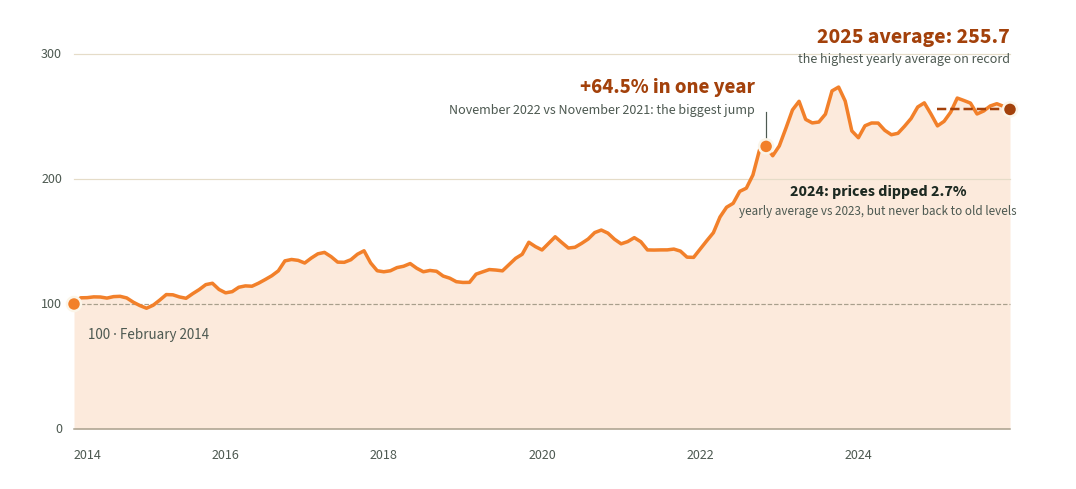

Saved charts/01_price_line.png


In [16]:
fig, ax = canvas(1056, 470)
X0, X1, BASE, PX_PER_POINT = 64, 1000, 420, 400 / 320

prices = food.loc["2014-02":"2025-12"]              # from the base month to the end of 2025 (the harvest year)
months = list(prices.index)
xs = [X0 + (X1 - X0) * i / (len(months) - 1) for i in range(len(months))]
ys = [BASE - value * PX_PER_POINT for value in prices]
X = dict(zip(months, xs))
Y = dict(zip(months, ys))

for level in [100, 200, 300]:                        # grid lines and their labels
    y = BASE - level * PX_PER_POINT
    style = "--" if level == 100 else "-"
    ax.plot([X0, X1], [y, y], style, color=C["axis"] if level == 100 else C["grid"], lw=1.2 * PT)
    text(ax, 52, y, str(level), 14, C["grey_text"], ha="right")
ax.plot([X0, X1], [BASE, BASE], color=C["axis"], lw=1.5 * PT)
text(ax, 52, BASE, "0", 14, C["grey_text"], ha="right")
for year in range(2014, 2025, 2):                    # year labels under the axis
    month = "2014-02" if year == 2014 else f"{year}-01"
    text(ax, X[month], 446, str(year), 14, C["grey_text"], ha="left" if year == 2014 else "center")

ax.fill_between(xs, ys, BASE, color=C["price"], alpha=0.16, linewidth=0)
ax.plot(xs, ys, color=C["price"], lw=3.5 * PT, solid_joinstyle="round", solid_capstyle="round")


def dot(month):
    ax.add_patch(Circle((X[month], Y[month]), 7, facecolor=C["price"], edgecolor=C["cream"], linewidth=2.5 * PT, zorder=5))


# Start
dot("2014-02")
text(ax, 78, Y["2014-02"] + 30, f"{prices.iloc[0]:.0f} · February 2014", 15, C["grey_text"])
# Biggest jump in one year
peak = yearly_change.idxmax()
dot(peak)
ax.plot([X[peak], X[peak]], [Y[peak] - 8, Y[peak] - 34], color=C["grey_text"], lw=1.2 * PT)
peak_date = pd.Timestamp(peak)
text(ax, X[peak] - 11, 78, f"{yearly_change.max():+.1f}% in one year", 21, C["price_text"], "bold", "right")
text(ax, X[peak] - 11, 101, f"{peak_date:%B %Y} vs {peak_date - pd.DateOffset(years=1):%B %Y}: the biggest jump",
     14, C["grey_text"], ha="right")
# The 2024 dip
dip = pct_change(yearly_avg[2024], yearly_avg[2023])
text(ax, X["2024-07"] - 20, 182, f"2024: prices dipped {abs(dip):.1f}%", 16, C["ink"], "bold", "center")
text(ax, X["2024-07"] - 20, 202, "yearly average vs 2023, but never back to old levels", 13, C["grey_text"], ha="center")
# 2025: a dashed line at the yearly average, the highest yearly average ever
avg_y = BASE - yearly_avg[2025] * PX_PER_POINT
ax.plot([X["2025-01"], X["2025-12"]], [avg_y, avg_y], "--", color=C["price_text"], lw=2.5 * PT)
ax.add_patch(Circle((X["2025-12"], avg_y), 7, facecolor=C["price_text"], edgecolor=C["cream"], linewidth=2.5 * PT, zorder=5))
text(ax, 1000, 28, f"2025 average: {yearly_avg[2025]:.1f}", 22, C["price_text"], "bold", "right")
text(ax, 1000, 50, "the highest yearly average on record", 14, C["grey_text"], ha="right")

save(fig, "01_price_line")

## Step 14: The harvest bars (panel 2)

The scale is **104 px for every 1 million tonnes**, the same as the cheat sheet. Every bar starts at the same x (90), so they all start from zero.

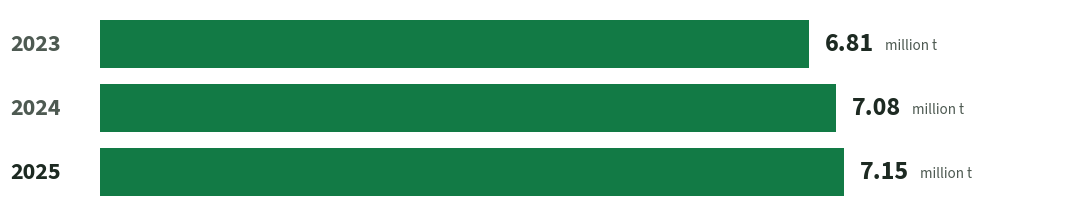

Saved charts/02_harvest_bars.png


In [17]:
fig, ax = canvas(1056, 200)
SCALE = 104                                          # px per million tonnes
for row, year in enumerate([2023, 2024, 2025]):
    top = 10 + row * 64
    width = harvest[year] / 1e6 * SCALE
    text(ax, 0, top + 24, str(year), 24, C["ink"] if year == 2025 else C["grey_text"], "bold")
    bar(ax, 90, top, width, 48, C["harvest"])
    text(ax, 90 + width + 16, top + 24, f"{harvest[year] / 1e6:.2f}", 26, C["ink"], "bold")
    text(ax, 90 + width + 76, top + 26, "million t", 15, C["grey_text"])
save(fig, "02_harvest_bars")

## Step 15: The gap (panel 3)

The **same scale** for both bars, **124 px per 1%**, so the orange bar really is about 4 times longer than the green one. `\n` inside a label starts a new line.

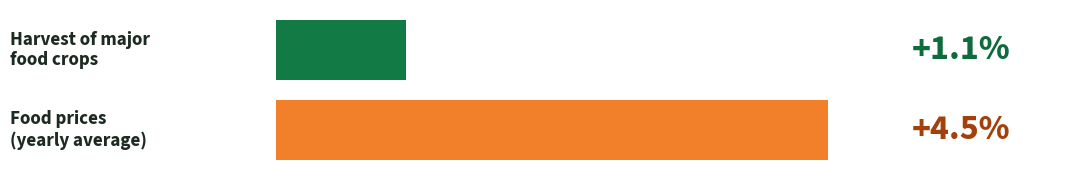

Saved charts/03_gap_bars.png


In [18]:
fig, ax = canvas(1056, 160)
SCALE = 124                                          # px per 1%
rows = [("Harvest of major\nfood crops", pct_change(harvest[2025], harvest[2024]), C["harvest"], C["harvest_text"]),
        ("Food prices\n(yearly average)", pct_change(yearly_avg[2025], yearly_avg[2024]), C["price"], C["price_text"])]
for row, (label, change, color, text_color) in enumerate(rows):
    top = 10 + row * 80
    text(ax, 0, top + 30, label, 19, C["ink"], "bold")
    bar(ax, 266, top, change * SCALE, 60, color)
    text(ax, 902, top + 30, f"{change:+.1f}%", 36, text_color, "bold")
save(fig, "03_gap_bars")

## Step 16: Crop by crop (panel 4)

A **diverging** bar chart: falls go **left** of the zero line in orange, rises go **right** in green, with the same scale (**33 px per 1%**) on both sides. `crops` is already sorted from the biggest fall to the biggest rise (Step 5). The first 48 px on the left are left empty for the crop icons added in Canva.

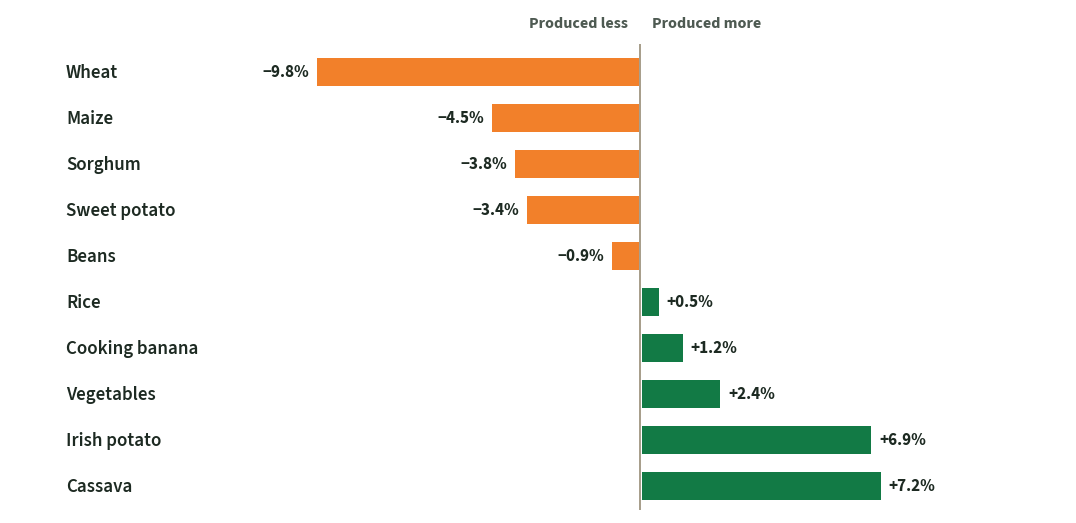

Saved charts/04_crop_by_crop.png


In [19]:
fig, ax = canvas(1056, 504)
SCALE, ZERO = 33, 630                                # px per 1%, x of the zero line
text(ax, ZERO - 12, 14, "Produced less", 16, C["grey_text"], "bold", "right")
text(ax, ZERO + 12, 14, "Produced more", 16, C["grey_text"], "bold")
ax.plot([ZERO, ZERO], [36, 500], color=C["axis"], lw=2 * PT)

for row, (crop, change) in enumerate(zip(crops["crop"], crops["change %"])):
    top = 40 + row * 46
    width = abs(change) * SCALE
    label = f"{change:+.1f}%".replace("-", "−")      # a proper minus sign
    text(ax, 56, top + 23, crop, 19, C["ink"], "semibold")
    if change < 0:
        bar(ax, ZERO - width, top + 9, width, 28, C["price"])
        text(ax, ZERO - width - 8, top + 23, label, 17, C["ink"], "bold", "right")
    else:
        bar(ax, ZERO + 2, top + 9, width, 28, C["harvest"])
        text(ax, ZERO + 2 + width + 8, top + 23, label, 17, C["ink"], "bold")
save(fig, "04_crop_by_crop")

## Step 17: The land grid (panel 5)

100 squares, one for each 1% of Rwanda's land. Two loops (rows inside columns) place them on a 10 × 10 grid. We count squares from the **bottom-right**, and colour the first 59 green.

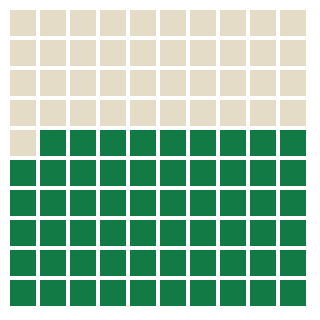

Saved charts/05_land_grid.png


In [20]:
fig, ax = canvas(300, 300)
green_squares = round(farmland)                      # 58.9% → 59 squares
for line in range(10):                               # 10 rows, top to bottom
    for column in range(10):                         # 10 squares in each row
        number = (9 - line) * 10 + (9 - column)      # 0 = bottom-right square
        color = C["harvest"] if number < green_squares else C["empty"]
        bar(ax, column * 30, line * 30, 26, 26, color)
save(fig, "05_land_grid")

## Step 18: The plates (panel 6)

Each plate is a **pie slice** of share × 360°, starting at 12 o'clock and growing clockwise so rural's 48.0% is a 172.9° slice.


rural: 48.0% on food → slice of 172.9°


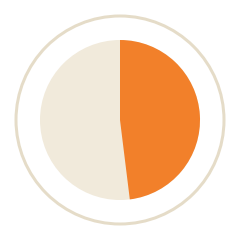

Saved charts/06_plate_rural.png
all_rwanda: 39.0% on food → slice of 140.5°


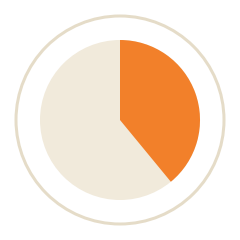

Saved charts/06_plate_all_rwanda.png
urban: 27.4% on food → slice of 98.6°


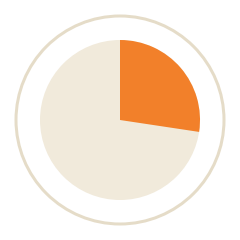

Saved charts/06_plate_urban.png


In [21]:
for name, rows in [("rural", rural), ("all_rwanda", all_rwanda), ("urban", urban)]:
    share = food_share(rows)                         # e.g. 48.04 (%)
    fig, ax = canvas(220, 220)
    ax.add_patch(Circle((110, 110), 104, facecolor="white", edgecolor=C["grid"], linewidth=3 * PT))
    ax.add_patch(Circle((110, 110), 80, facecolor=C["plate"], linewidth=0))
    ax.add_patch(Wedge((110, 110), 80, -90, -90 + 360 * share / 100, facecolor=C["price"], linewidth=0))
    print(f"{name}: {share:.1f}% on food → slice of {360 * share / 100:.1f}°")
    save(fig, f"06_plate_{name}")

## Step 19: Room to grow (closing panel)

Each bar is a full **track** (100%) with the share filled in, at **5.2 px per 1%**. The text is light-coloured, because this panel sits on the **dark green** background. On a white preview the words look faint, but they'll be clear once you place the PNG on dark green in Canva.

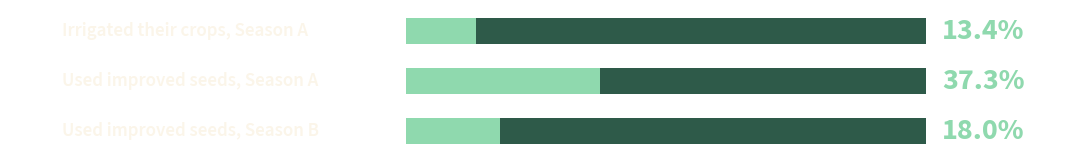

Saved charts/07_room_to_grow.png


In [22]:
fig, ax = canvas(1056, 140)
SCALE = 5.2                                          # px per 1% (520 px = 100%)
rows = [("Irrigated their crops, Season A", practices["Irrigation"]["2025 A"]),
        ("Used improved seeds, Season A", inputs["Improved seeds"]["2025 A"]),
        ("Used improved seeds, Season B", inputs["Improved seeds"]["2025 B"])]
for row, (label, share) in enumerate(rows):
    top = 8 + row * 50
    text(ax, 52, top + 13, label, 19, C["cream"], "semibold")
    bar(ax, 396, top, 100 * SCALE, 26, C["track"])
    bar(ax, 396, top, share * SCALE, 26, C["mint"])
    text(ax, 932, top + 13, f"{r(share):.1f}%", 30, C["mint"], "bold")
save(fig, "07_room_to_grow")